# Welcome to Modal notebooks!

Write Python code and collaborate in real time. Your code runs in Modal's
**serverless cloud**, and anyone in the same workspace can join.

This notebook comes with some common Python libraries installed. Run
cells with `Shift+Enter`.

In [1]:
!pip install "kagglehub<1.0.0" "protobuf>=5.29,<6.0" -q


[notice] A new release of pip is available: 24.3.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip



[notice] A new release of pip is available: 24.3.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Loaded 2,260,701 rows, 151 columns
Train: 826,602 | Test: 518,334
Setup complete.

Training XGBoost default predictor (Method 2)...
XGBoost trained | best iteration: 56

=== Method 2: XGBoost Risk-Constrained Policy ===
Evaluating Train (826,602 loans)...

[Train] FINAL RESULTS
  Total profit   : $86,461,946
  Approved loans : 43,413 (5.3%)
  NPL ratio      : 3.19%  (target < 5%)
  Avg profit/loan: $1,991.61
  Action dist    : reject=783,189 | low=0 | mid=497 | high=42,916

Evaluating Test (518,334 loans)...

[Test] FINAL RESULTS
  Total profit   : $55,997,759
  Approved loans : 31,408 (6.1%)
  NPL ratio      : 4.01%  (target < 5%)
  Avg profit/loan: $1,782.91
  Action dist    : reject=486,926 | low=0 | mid=509 | high=30,899

Method 2 arrays saved.


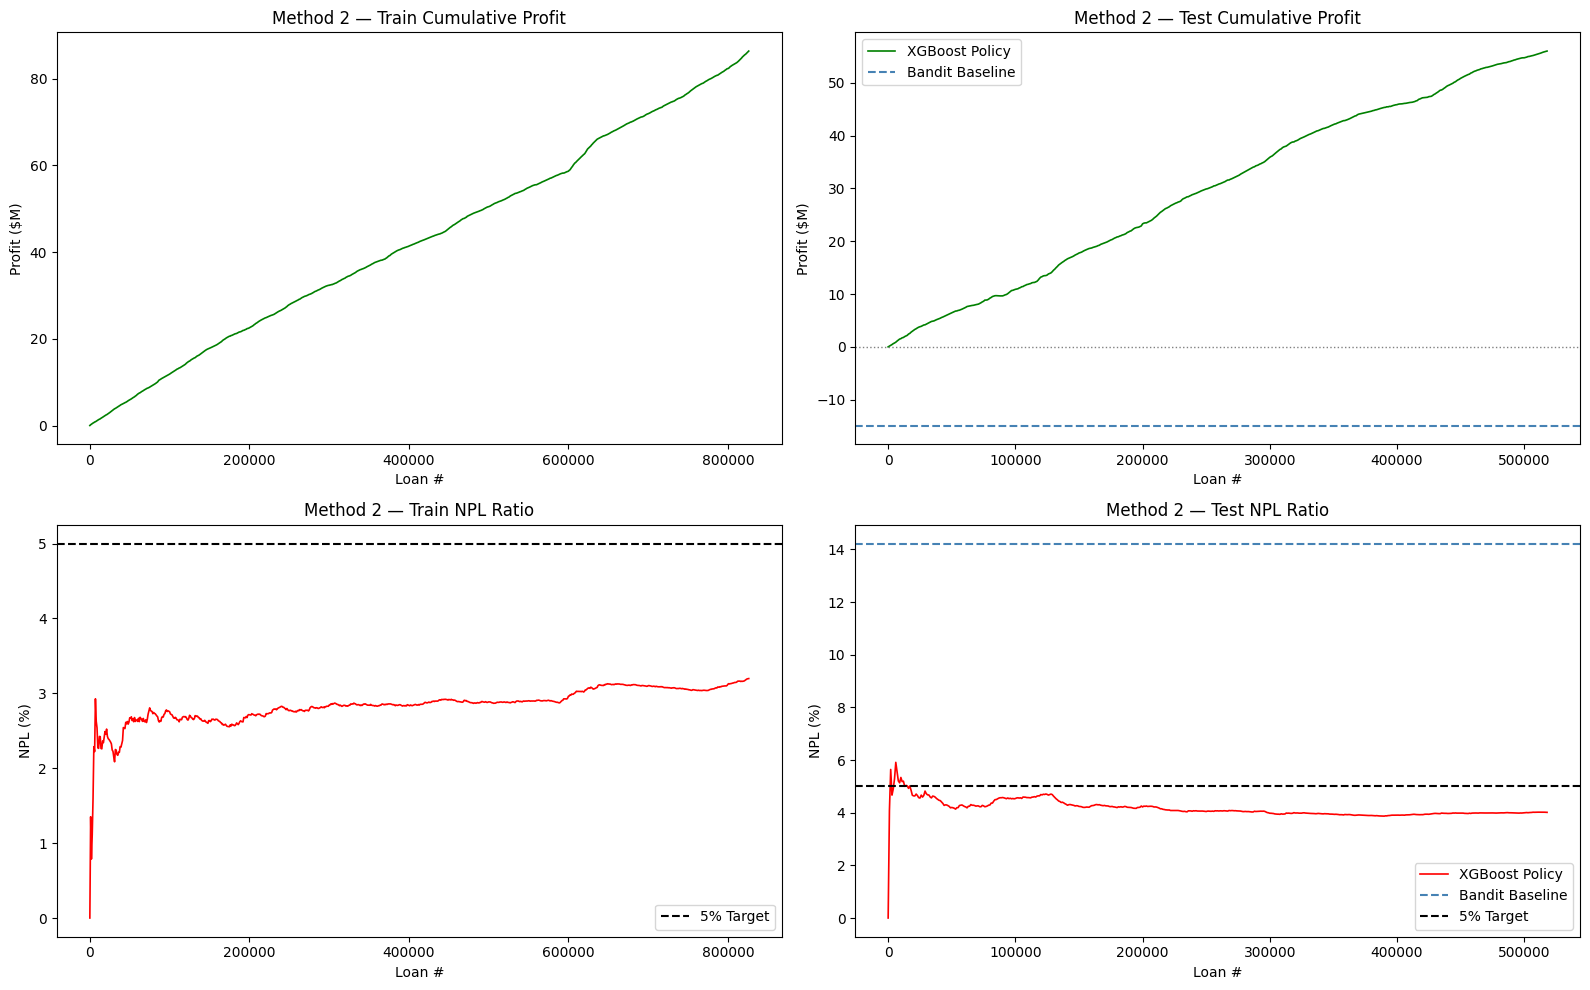

Plot saved to /root/method2_results.png

Method 2 Final Summary:
  Train | profit=$86,461,946 | NPL=3.19%
  Test  | profit=$55,997,759  | NPL=4.01%

Training XGBoost default predictor (Method 3)...
XGBoost trained | best iteration: 56

=== Method 3: XGBoost Unconstrained Policy (Ablation) ===
Evaluating Train (826,602 loans)...

[Train] FINAL RESULTS
  Total profit   : $-564,203,478
  Approved loans : 826,602 (100.0%)
  NPL ratio      : 18.42%  (target < 5%)
  Avg profit/loan: $-682.56
  Action dist    : reject=0 | low=497 | mid=24,202 | high=801,903

Evaluating Test (518,334 loans)...

[Test] FINAL RESULTS
  Total profit   : $-754,943,322
  Approved loans : 518,334 (100.0%)
  NPL ratio      : 22.42%  (target < 5%)
  Avg profit/loan: $-1,456.48
  Action dist    : reject=0 | low=509 | mid=18,336 | high=499,489

Method 3 arrays saved.


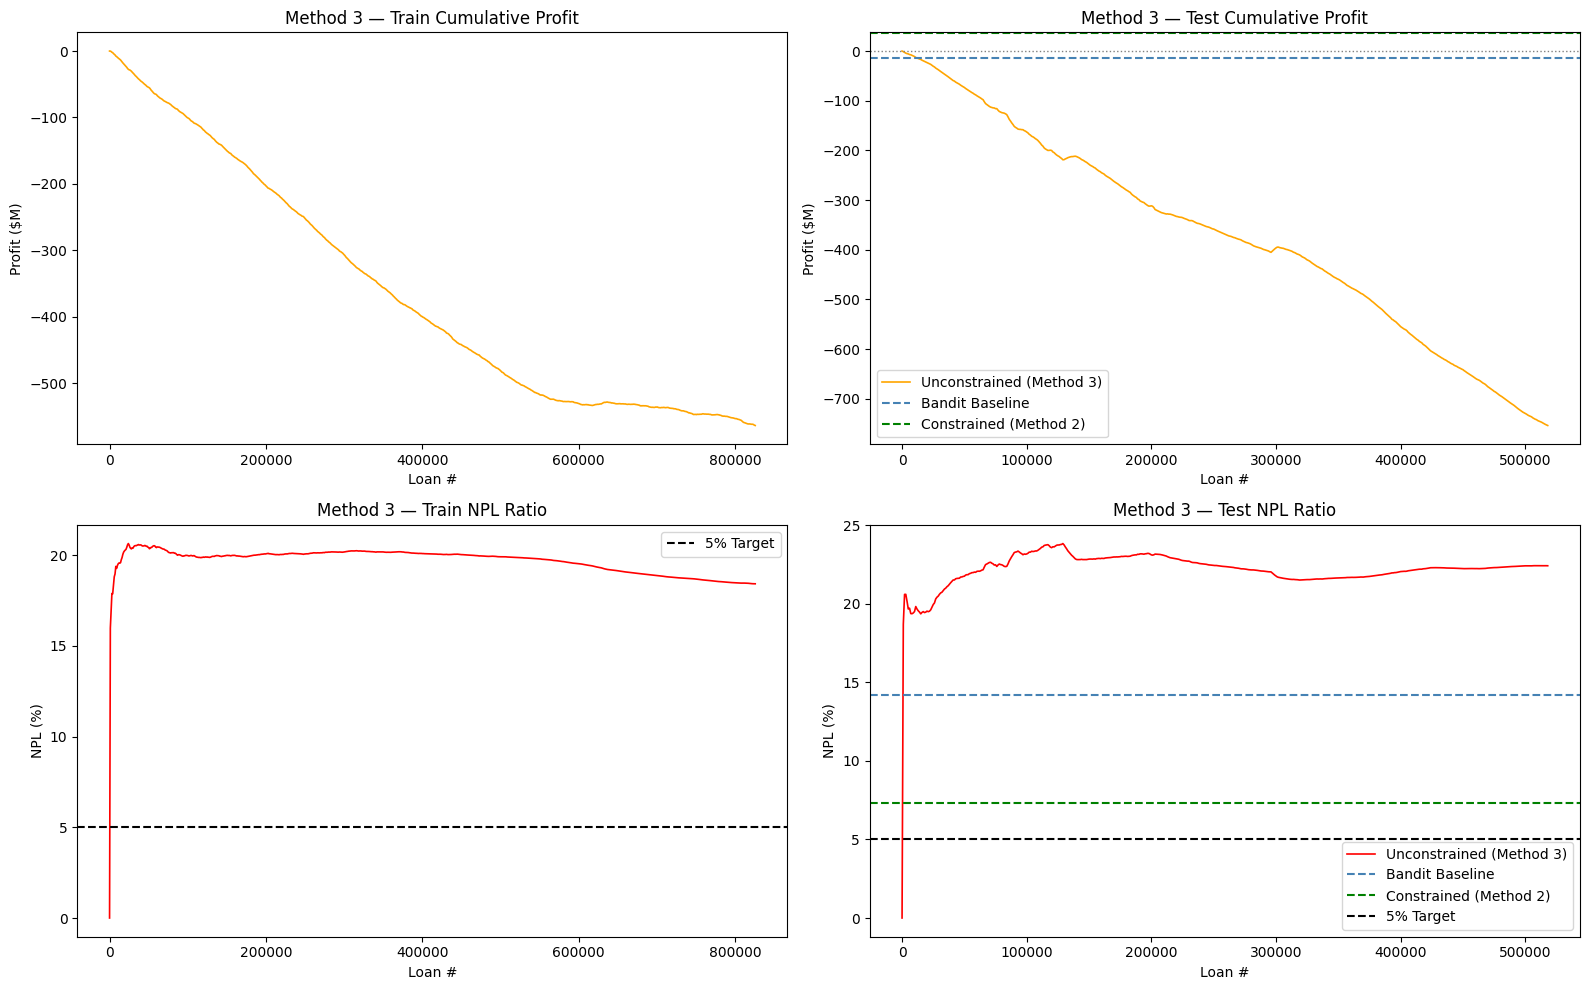

Plot saved to /root/method3_results.png

Method 3 Final Summary:
  Train | profit=$-564,203,478 | NPL=18.42%
  Test  | profit=$-754,943,322  | NPL=22.42%

FINAL COMPARISON TABLE
  Method 1 (Bandit)        | profit= $    126,661,332 | NPL= 12.35%
  Method 2 (Constrained)   | profit= $     55,997,759 | NPL= 4.01%
  Method 3 (Unconstrained) | profit= $   -754,943,322 | NPL= 22.42%


In [6]:
!pip install kagglehub pandas numpy torch scikit-learn matplotlib xgboost -q

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from collections import deque
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import kagglehub
from xgboost import XGBClassifier

SEED = 42
random.seed(SEED)
np.random.seed(SEED)


# ══════════════════════════════════════════════════════
# 1. LOAD DATA
# ══════════════════════════════════════════════════════
print("Downloading LendingClub data from Kaggle...")
path = kagglehub.dataset_download("wordsforthewise/lending-club")
df = pd.read_csv(
    os.path.join(path, "accepted_2007_to_2018q4.csv", "accepted_2007_to_2018Q4.csv"),
    low_memory=False
)
print(f"Loaded {len(df):,} rows, {df.shape[1]} columns")


# ══════════════════════════════════════════════════════
# 2. PREPROCESS
# ══════════════════════════════════════════════════════
df = df[df["loan_status"].isin(["Fully Paid", "Charged Off"])].copy()
df["default"] = (df["loan_status"] == "Charged Off").astype(int)

# Pull raw columns needed for feature engineering + meta columns
raw_cols = ["fico_range_low", "dti", "annual_inc", "grade", "int_rate",
            "loan_amnt", "installment", "issue_d"]
df = df[raw_cols + ["default"]].copy()

# --- Feature Engineering ---

# grade → ordinal int (A=0, B=1, ..., G=6)
grade_map = {"A": 0, "B": 1, "C": 2, "D": 3, "E": 4, "F": 5, "G": 6}
df["grade"] = df["grade"].map(grade_map)

# total_interest_burden: estimated total interest paid over loan life
# approximated as int_rate (%) * loan_amnt
df["total_interest_burden"] = (df["int_rate"] / 100) * df["loan_amnt"]

# payment_to_income: monthly installment as fraction of monthly income
df["annual_inc"] = df["annual_inc"].clip(lower=1)          # avoid div/0
df["payment_to_income"] = df["installment"] / (df["annual_inc"] / 12)

# Log-transform skewed numerics
df["dti"]                   = np.log1p(df["dti"].clip(lower=0))
df["total_interest_burden"] = np.log1p(df["total_interest_burden"].clip(lower=0))
df["payment_to_income"]     = np.log1p(df["payment_to_income"].clip(lower=0))

# Drop nulls
df = df.dropna()

# Feature list — order matters: fico_range_low must stay index 0 for policy()
features = ["fico_range_low", "total_interest_burden", "grade", "payment_to_income", "dti"]

# Temporal train/test split
df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y")
train_df = df[df["issue_d"] < "2016-01-01"].copy().reset_index(drop=True)
test_df  = df[df["issue_d"] >= "2016-01-01"].copy().reset_index(drop=True)

print(f"Train: {len(train_df):,} | Test: {len(test_df):,}")


# ══════════════════════════════════════════════════════
# 3. ENVIRONMENT (needed for RATE_TIERS reference)
# ══════════════════════════════════════════════════════
class LendingEnvDQN:
    RATE_TIERS = {1: 0.08, 2: 0.13, 3: 0.19}

print("Setup complete.")


# ══════════════════════════════════════════════════════════════════════════════
# METHOD 2: XGBoost Risk-Constrained Policy
# ══════════════════════════════════════════════════════════════════════════════

# ── HYPERPARAMETERS ──────────────────────────────────────
REJECT_THRESH = 0.20
MID_THRESH    = 0.08
HIGH_THRESH   = 0.10
FICO_CUTOFF   = 700

# ── TRAIN XGBOOST ────────────────────────────────────────
print("\nTraining XGBoost default predictor (Method 2)...")
X_train = train_df[features].values
y_train = train_df["default"].values
X_test  = test_df[features].values
y_test  = test_df["default"].values

xgb_m2 = XGBClassifier(
    n_estimators          = 500,
    max_depth             = 6,
    learning_rate         = 0.05,
    subsample             = 0.8,
    colsample_bytree      = 0.8,
    scale_pos_weight      = (y_train == 0).sum() / (y_train == 1).sum(),
    random_state          = SEED,
    eval_metric           = "auc",
    early_stopping_rounds = 20,
    verbosity             = 0,
)
xgb_m2.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=False,
)
print(f"XGBoost trained | best iteration: {xgb_m2.best_iteration}")


# ── POLICY ───────────────────────────────────────────────
def policy_m2(p_default, feats):
    fico    = feats[:, 0]   # fico_range_low is index 0
    actions = np.where(p_default > REJECT_THRESH, 0,
              np.where(p_default > HIGH_THRESH,   3,
              np.where(p_default > MID_THRESH,    2,
                                                  1)))
    actions = np.where(fico < FICO_CUTOFF, 0, actions)
    return actions


# ── EVALUATION ───────────────────────────────────────────
def evaluate_xgb_m2(df, X, split_name="Test"):
    print(f"Evaluating {split_name} ({len(df):,} loans)...")
    p_default = xgb_m2.predict_proba(X)[:, 1]
    actions   = policy_m2(p_default, X)
    defaulted = df["default"].values
    loan_amnt = df["loan_amnt"].values
    rates     = np.array([LendingEnvDQN.RATE_TIERS.get(a, 0) for a in actions])
    rewards   = np.where(actions == 0, 0.0,
                np.where(defaulted == 1, -loan_amnt, rates * loan_amnt))

    approved     = actions != 0
    defaults     = (actions != 0) & (defaulted == 1)
    profit_curve = np.cumsum(rewards)
    n_approved   = np.cumsum(approved)
    n_defaults   = np.cumsum(defaults)

    with np.errstate(invalid="ignore"):
        npl_curve = np.where(n_approved > 0, n_defaults / n_approved * 100, 0)

    total_profit   = float(profit_curve[-1])
    final_npl      = float(n_defaults[-1] / max(n_approved[-1], 1))
    final_approved = int(n_approved[-1])
    unique, counts = np.unique(actions, return_counts=True)
    action_dist    = dict(zip(unique, counts))

    print(f"\n{'='*55}")
    print(f"[{split_name}] FINAL RESULTS")
    print(f"  Total profit   : ${total_profit:,.0f}")
    print(f"  Approved loans : {final_approved:,} ({final_approved/len(df)*100:.1f}%)")
    print(f"  NPL ratio      : {final_npl:.2%}  (target < 5%)")
    print(f"  Avg profit/loan: ${total_profit/max(final_approved,1):,.2f}")
    print(f"  Action dist    : reject={action_dist.get(0,0):,} | low={action_dist.get(1,0):,} | mid={action_dist.get(2,0):,} | high={action_dist.get(3,0):,}")
    print(f"{'='*55}\n")
    return profit_curve, npl_curve, {
        "profit": total_profit, "npl": final_npl, "approved": final_approved
    }


# ── RUN ──────────────────────────────────────────────────
print("\n=== Method 2: XGBoost Risk-Constrained Policy ===")
m2_train_curve, m2_train_npl, m2_train_metrics = evaluate_xgb_m2(train_df, X_train, "Train")
m2_test_curve,  m2_test_npl,  m2_test_metrics  = evaluate_xgb_m2(test_df,  X_test,  "Test")

np.save("/root/m2_train_curve.npy", m2_train_curve)
np.save("/root/m2_test_curve.npy",  m2_test_curve)
np.save("/root/m2_train_npl.npy",   m2_train_npl)
np.save("/root/m2_test_npl.npy",    m2_test_npl)
print("Method 2 arrays saved.")


# ── PLOT ─────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
tr_x = np.arange(0, len(m2_train_curve), 1000)
te_x = np.arange(0, len(m2_test_curve),  1000)

axes[0][0].plot(tr_x, m2_train_curve[tr_x] / 1e6, color="green", linewidth=1.2)
axes[0][0].set_title("Method 2 — Train Cumulative Profit")
axes[0][0].set_xlabel("Loan #"); axes[0][0].set_ylabel("Profit ($M)")

axes[0][1].plot(te_x, m2_test_curve[te_x] / 1e6, color="green", linewidth=1.2, label="XGBoost Policy")
axes[0][1].axhline(y=-14.883, color="steelblue", linestyle="--", linewidth=1.5, label="Bandit Baseline")
axes[0][1].axhline(y=0, color="gray", linestyle=":", linewidth=1)
axes[0][1].set_title("Method 2 — Test Cumulative Profit")
axes[0][1].set_xlabel("Loan #"); axes[0][1].set_ylabel("Profit ($M)")
axes[0][1].legend()

axes[1][0].plot(tr_x, m2_train_npl[tr_x], color="red", linewidth=1.2)
axes[1][0].axhline(y=5.0, color="black", linestyle="--", linewidth=1.5, label="5% Target")
axes[1][0].set_title("Method 2 — Train NPL Ratio")
axes[1][0].set_xlabel("Loan #"); axes[1][0].set_ylabel("NPL (%)")
axes[1][0].legend()

axes[1][1].plot(te_x, m2_test_npl[te_x], color="red", linewidth=1.2, label="XGBoost Policy")
axes[1][1].axhline(y=14.22, color="steelblue", linestyle="--", linewidth=1.5, label="Bandit Baseline")
axes[1][1].axhline(y=5.0,   color="black",     linestyle="--", linewidth=1.5, label="5% Target")
axes[1][1].set_title("Method 2 — Test NPL Ratio")
axes[1][1].set_xlabel("Loan #"); axes[1][1].set_ylabel("NPL (%)")
axes[1][1].legend()

plt.tight_layout()
plt.savefig("/root/method2_results.png", dpi=150, bbox_inches="tight")
plt.show()
print("Plot saved to /root/method2_results.png")
print(f"\nMethod 2 Final Summary:")
print(f"  Train | profit=${m2_train_metrics['profit']:,.0f} | NPL={m2_train_metrics['npl']:.2%}")
print(f"  Test  | profit=${m2_test_metrics['profit']:,.0f}  | NPL={m2_test_metrics['npl']:.2%}")


# ══════════════════════════════════════════════════════════════════════════════
# METHOD 3: XGBoost Unconstrained Policy (Ablation)
# ══════════════════════════════════════════════════════════════════════════════

# ── HYPERPARAMETERS — unconstrained ablation ─────────────
REJECT_THRESH = 1.0    # never reject
MID_THRESH    = 0.10
HIGH_THRESH   = 0.18
FICO_CUTOFF   = 0      # no FICO floor

# ── TRAIN XGBOOST ────────────────────────────────────────
print("\nTraining XGBoost default predictor (Method 3)...")
xgb_m3 = XGBClassifier(
    n_estimators          = 500,
    max_depth             = 6,
    learning_rate         = 0.05,
    subsample             = 0.8,
    colsample_bytree      = 0.8,
    scale_pos_weight      = (y_train == 0).sum() / (y_train == 1).sum(),
    random_state          = SEED,
    eval_metric           = "auc",
    early_stopping_rounds = 20,
    verbosity             = 0,
)
xgb_m3.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=False,
)
print(f"XGBoost trained | best iteration: {xgb_m3.best_iteration}")


# ── POLICY ───────────────────────────────────────────────
def policy_m3(p_default, feats):
    fico    = feats[:, 0]   # fico_range_low is index 0
    actions = np.where(p_default > REJECT_THRESH, 0,
              np.where(p_default > HIGH_THRESH,   3,
              np.where(p_default > MID_THRESH,    2,
                                                  1)))
    actions = np.where(fico < FICO_CUTOFF, 0, actions)
    return actions


# ── EVALUATION ───────────────────────────────────────────
def evaluate_xgb_m3(df, X, split_name="Test"):
    print(f"Evaluating {split_name} ({len(df):,} loans)...")
    p_default = xgb_m3.predict_proba(X)[:, 1]
    actions   = policy_m3(p_default, X)
    defaulted = df["default"].values
    loan_amnt = df["loan_amnt"].values
    rates     = np.array([LendingEnvDQN.RATE_TIERS.get(a, 0) for a in actions])
    rewards   = np.where(actions == 0, 0.0,
                np.where(defaulted == 1, -loan_amnt, rates * loan_amnt))

    approved     = actions != 0
    defaults     = (actions != 0) & (defaulted == 1)
    profit_curve = np.cumsum(rewards)
    n_approved   = np.cumsum(approved)
    n_defaults   = np.cumsum(defaults)

    with np.errstate(invalid="ignore"):
        npl_curve = np.where(n_approved > 0, n_defaults / n_approved * 100, 0)

    total_profit   = float(profit_curve[-1])
    final_npl      = float(n_defaults[-1] / max(n_approved[-1], 1))
    final_approved = int(n_approved[-1])
    unique, counts = np.unique(actions, return_counts=True)
    action_dist    = dict(zip(unique, counts))

    print(f"\n{'='*55}")
    print(f"[{split_name}] FINAL RESULTS")
    print(f"  Total profit   : ${total_profit:,.0f}")
    print(f"  Approved loans : {final_approved:,} ({final_approved/len(df)*100:.1f}%)")
    print(f"  NPL ratio      : {final_npl:.2%}  (target < 5%)")
    print(f"  Avg profit/loan: ${total_profit/max(final_approved,1):,.2f}")
    print(f"  Action dist    : reject={action_dist.get(0,0):,} | low={action_dist.get(1,0):,} | mid={action_dist.get(2,0):,} | high={action_dist.get(3,0):,}")
    print(f"{'='*55}\n")
    return profit_curve, npl_curve, {
        "profit": total_profit, "npl": final_npl, "approved": final_approved
    }


# ── RUN ──────────────────────────────────────────────────
print("\n=== Method 3: XGBoost Unconstrained Policy (Ablation) ===")
m3_train_curve, m3_train_npl, m3_train_metrics = evaluate_xgb_m3(train_df, X_train, "Train")
m3_test_curve,  m3_test_npl,  m3_test_metrics  = evaluate_xgb_m3(test_df,  X_test,  "Test")

np.save("/root/m3_train_curve.npy", m3_train_curve)
np.save("/root/m3_test_curve.npy",  m3_test_curve)
np.save("/root/m3_train_npl.npy",   m3_train_npl)
np.save("/root/m3_test_npl.npy",    m3_test_npl)
print("Method 3 arrays saved.")


# ── PLOT ─────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
tr_x = np.arange(0, len(m3_train_curve), 1000)
te_x = np.arange(0, len(m3_test_curve),  1000)

axes[0][0].plot(tr_x, m3_train_curve[tr_x] / 1e6, color="orange", linewidth=1.2)
axes[0][0].set_title("Method 3 — Train Cumulative Profit")
axes[0][0].set_xlabel("Loan #"); axes[0][0].set_ylabel("Profit ($M)")

axes[0][1].plot(te_x, m3_test_curve[te_x] / 1e6, color="orange", linewidth=1.2, label="Unconstrained (Method 3)")
axes[0][1].axhline(y=-14.883, color="steelblue", linestyle="--", linewidth=1.5, label="Bandit Baseline")
axes[0][1].axhline(y=35.662,  color="green",     linestyle="--", linewidth=1.5, label="Constrained (Method 2)")
axes[0][1].axhline(y=0, color="gray", linestyle=":", linewidth=1)
axes[0][1].set_title("Method 3 — Test Cumulative Profit")
axes[0][1].set_xlabel("Loan #"); axes[0][1].set_ylabel("Profit ($M)")
axes[0][1].legend()

axes[1][0].plot(tr_x, m3_train_npl[tr_x], color="red", linewidth=1.2)
axes[1][0].axhline(y=5.0, color="black", linestyle="--", linewidth=1.5, label="5% Target")
axes[1][0].set_title("Method 3 — Train NPL Ratio")
axes[1][0].set_xlabel("Loan #"); axes[1][0].set_ylabel("NPL (%)")
axes[1][0].legend()

axes[1][1].plot(te_x, m3_test_npl[te_x], color="red", linewidth=1.2, label="Unconstrained (Method 3)")
axes[1][1].axhline(y=14.22, color="steelblue", linestyle="--", linewidth=1.5, label="Bandit Baseline")
axes[1][1].axhline(y=7.31,  color="green",     linestyle="--", linewidth=1.5, label="Constrained (Method 2)")
axes[1][1].axhline(y=5.0,   color="black",     linestyle="--", linewidth=1.5, label="5% Target")
axes[1][1].set_title("Method 3 — Test NPL Ratio")
axes[1][1].set_xlabel("Loan #"); axes[1][1].set_ylabel("NPL (%)")
axes[1][1].legend()

plt.tight_layout()
plt.savefig("/root/method3_results.png", dpi=150, bbox_inches="tight")
plt.show()
print("Plot saved to /root/method3_results.png")

print(f"\nMethod 3 Final Summary:")
print(f"  Train | profit=${m3_train_metrics['profit']:,.0f} | NPL={m3_train_metrics['npl']:.2%}")
print(f"  Test  | profit=${m3_test_metrics['profit']:,.0f}  | NPL={m3_test_metrics['npl']:.2%}")

print(f"\n{'='*55}")
print(f"FINAL COMPARISON TABLE")
print(f"{'='*55}")
print(f"  Method 1 (Bandit)        | profit= ${126_661_332:>15,.0f} | NPL= 12.35%")
print(f"  Method 2 (Constrained)   | profit= ${m2_test_metrics['profit']:>15,.0f} | NPL= {m2_test_metrics['npl']:.2%}")
print(f"  Method 3 (Unconstrained) | profit= ${m3_test_metrics['profit']:>15,.0f} | NPL= {m3_test_metrics['npl']:.2%}")
print(f"{'='*55}")